In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
with open(os.path.expanduser('~/.kaggle/access_token'), 'w') as f:
    f.write('YOUR_TOKEN_HERE')

In [ ]:
!pip install -q --upgrade kaggle
!mkdir -p /content/drive/MyDrive/medical-image-classification/data/raw
!kaggle competitions download -c rsna-pneumonia-detection-challenge -p /content/drive/MyDrive/medical-image-classification/data/raw
!unzip -q /content/drive/MyDrive/medical-image-classification/data/raw/rsna-pneumonia-detection-challenge.zip -d /content/drive/MyDrive/medical-image-classification/data/raw
!rm /content/drive/MyDrive/medical-image-classification/data/raw/rsna-pneumonia-detection-challenge.zip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 10.8 MB/s eta 0:00:00
100% 3.66G/3.66G [02:58<00:00, 22.0MB/s]



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import os, sys

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


In [ ]:

base_dir = '/content/drive/MyDrive/medical-image-classification/data/raw'
train_dir = f'{base_dir}/stage_2_train_images'

labels = pd.read_csv(f'{base_dir}/stage_2_train_labels.csv')
classes = pd.read_csv(f'{base_dir}/stage_2_detailed_class_info.csv')

print(labels.shape, classes.shape)

(30227, 6) (30227, 2)


In [ ]:
print("Unique patients (labels):", labels['patientId'].nunique())
print("Unique patients (classes):", classes['patientId'].nunique())
print()
print("Target distribution (0=no pneumonia, 1=pneumonia):")
print(labels.drop_duplicates('patientId')['Target'].value_counts())
print()
print("3-class distribution:")
print(classes['class'].value_counts())

Unique patients (labels): 26684
Unique patients (classes): 26684

Target distribution (0=no pneumonia, 1=pneumonia):
Target
0    20672
1     6012
Name: count, dtype: int64

3-class distribution:
class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851
Name: count, dtype: int64


In [3]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 90.4 MB/s eta 0:00:00


In [ ]:

base_dir = '/content/drive/MyDrive/medical-image-classification/data/raw'
train_dir = f'{base_dir}/stage_2_train_images'

labels = pd.read_csv(f'{base_dir}/stage_2_train_labels.csv')
classes = pd.read_csv(f'{base_dir}/stage_2_detailed_class_info.csv')

print("labels:", labels.shape, "| classes:", classes.shape)
print("train images:", len(os.listdir(train_dir)))

labels: (30227, 6) | classes: (30227, 2)
train images: 26684


Checking for visual samples : 2 normal(Target:0) and 2 pneumonia (Target :1)

In [ ]:
import matplotlib.pyplot as plt

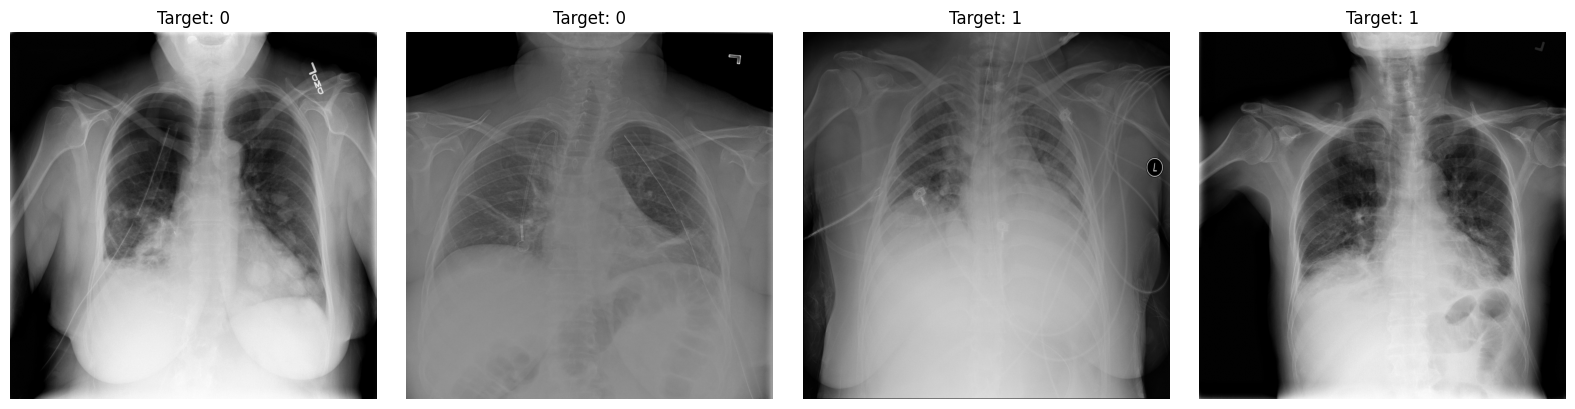

In [ ]:
sample_ids = pd.concat([
    labels[labels['Target'] == 0].drop_duplicates('patientId').head(2),
    labels[labels['Target'] == 1].drop_duplicates('patientId').head(2)
])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, row) in zip(axes, sample_ids.iterrows()):
    ds = pydicom.dcmread(f"{train_dir}/{row['patientId']}.dcm")
    ax.imshow(ds.pixel_array, cmap='gray')
    ax.set_title(f"Target: {row['Target']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

Checking the total numbers of corrupted files across the full training set

In [ ]:

import pydicom.errors

bad_files = []
for f in os.listdir(train_dir):
    try:
        pydicom.dcmread(os.path.join(train_dir, f))
    except Exception as e:
        bad_files.append((f, str(e)))

print("Corrupted files found:", len(bad_files))
if bad_files:
    print(bad_files[:10])

Corrupted files found: 0


In [ ]:
from sklearn.model_selection import train_test_split

patient_labels = labels.drop_duplicates('patientId')[['patientId', 'Target']]

train_ids, temp_ids = train_test_split(
    patient_labels, test_size=0.30, stratify=patient_labels['Target'], random_state=42
)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, stratify=temp_ids['Target'], random_state=42
)

print("Train:", len(train_ids), "| Pneumonia rate:", train_ids['Target'].mean().round(3))
print("Val:  ", len(val_ids), "| Pneumonia rate:", val_ids['Target'].mean().round(3))
print("Test: ", len(test_ids), "| Pneumonia rate:", test_ids['Target'].mean().round(3))

splits_dir = '/content/drive/MyDrive/medical-image-classification/data/splits'
os.makedirs(splits_dir, exist_ok=True)
train_ids.to_csv(f'{splits_dir}/train.csv', index=False)
val_ids.to_csv(f'{splits_dir}/val.csv', index=False)
test_ids.to_csv(f'{splits_dir}/test.csv', index=False)

Train: 18678 | Pneumonia rate: 0.225
Val:   4003 | Pneumonia rate: 0.225
Test:  4003 | Pneumonia rate: 0.225


Now let us do some image aumentation. Augment train data only and normalize dataset

In [ ]:
import torch
from torch.utils.data import Dataset
import pydicom
import numpy as np
import cv2

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class RSNAPneumoniaDataset(Dataset):
    """
    Loads RSNA chest X-ray DICOMs + binary pneumonia labels.
    split_df: dataframe with columns ['patientId', 'Target']
    """
    def __init__(self, split_df, image_dir, image_size=224, augment=False):
        self.df = split_df.reset_index(drop=True)
        self.image_dir = image_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        patient_id = row['patientId']
        target = row['Target']


        dcm_path = f"{self.image_dir}/{patient_id}.dcm"
        ds = pydicom.dcmread(dcm_path)
        img = ds.pixel_array.astype(np.float32)


        img = cv2.resize(img, (self.image_size, self.image_size))


        img = np.stack([img] * 3, axis=-1)


        if self.augment:
            img = self._augment(img)


        img = img / 255.0
        img = (img - IMAGENET_MEAN) / IMAGENET_STD


        img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
        target = torch.tensor(target, dtype=torch.float32)

        return img, target

    def _augment(self, img):

        if np.random.rand() < 0.5:
            img = np.fliplr(img).copy()


        if np.random.rand() < 0.5:
            angle = np.random.uniform(-8, 8)
            h, w = img.shape[:2]
            M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
            img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE)


        if np.random.rand() < 0.5:
            alpha = np.random.uniform(0.9, 1.1)
            beta = np.random.uniform(-10, 10)
            img = np.clip(img * alpha + beta, 0, 255)

        return img

In [ ]:
train_ds = RSNAPneumoniaDataset(train_ids, train_dir, augment=True)
val_ds = RSNAPneumoniaDataset(val_ids, train_dir, augment=False)

img, label = train_ds[0]
print("Image shape:", img.shape, "| dtype:", img.dtype)
print("Label:", label.item())
print("Pixel value range:", img.min().item(), "to", img.max().item())

Image shape: torch.Size([3, 224, 224]) | dtype: torch.float32
Label: 1.0
Pixel value range: -2.1179039478302 to 2.1908936500549316


In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            self._block(3, 32),
            self._block(32, 64),
            self._block(64, 128),
            self._block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(256, 1)

    def _block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        total += imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1


def validate(model, loader, criterion, device):
    model.eval()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            total += imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

In [ ]:

model = BaselineCNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

checkpoint_dir = '/content/drive/MyDrive/medical-image-classification/models'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = f'{checkpoint_dir}/baseline_cnn.pt'

max_epochs = 20
patience = 4
best_val_loss = float('inf')
epochs_no_improve = 0
history = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model, val_loader, criterion, device)

    history.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'train_acc': train_acc, 'val_acc': val_acc,
        'train_prec': train_prec, 'val_prec': val_prec,
        'train_rec': train_rec, 'val_rec': val_rec,
        'train_f1': train_f1, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), checkpoint_path)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
            break

Epoch 1: train_loss=0.4624 val_loss=0.4418 | val_acc=0.7857 val_prec=0.6236 val_rec=0.1231 val_f1=0.2056
  -> saved new best model
Epoch 2: train_loss=0.4448 val_loss=0.4278 | val_acc=0.8016 val_prec=0.6093 val_rec=0.3337 val_f1=0.4312
  -> saved new best model
Epoch 3: train_loss=0.4359 val_loss=0.4207 | val_acc=0.8029 val_prec=0.6890 val_rec=0.2284 val_f1=0.3430
  -> saved new best model
Epoch 4: train_loss=0.4319 val_loss=0.4183 | val_acc=0.8039 val_prec=0.6376 val_rec=0.3004 val_f1=0.4084
  -> saved new best model
Epoch 5: train_loss=0.4288 val_loss=0.4148 | val_acc=0.8021 val_prec=0.6165 val_rec=0.3226 val_f1=0.4236
  -> saved new best model
Epoch 6: train_loss=0.4227 val_loss=0.4048 | val_acc=0.8124 val_prec=0.6200 val_rec=0.4324 val_f1=0.5095
  -> saved new best model
Epoch 7: train_loss=0.4214 val_loss=0.4203 | val_acc=0.8014 val_prec=0.7149 val_rec=0.1973 val_f1=0.3093
Epoch 8: train_loss=0.4201 val_loss=0.3956 | val_acc=0.8196 val_prec=0.6510 val_rec=0.4302 val_f1=0.5180
  ->

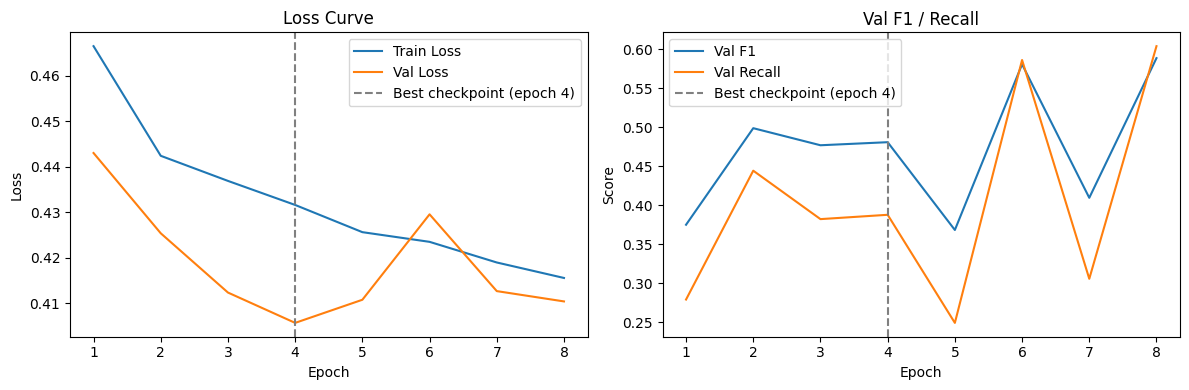

In [ ]:
epochs = [h['epoch'] for h in history]
train_loss = [h['train_loss'] for h in history]
val_loss = [h['val_loss'] for h in history]
val_f1 = [h['val_f1'] for h in history]
val_rec = [h['val_rec'] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_loss, label='Train Loss')
axes[0].plot(epochs, val_loss, label='Val Loss')
axes[0].axvline(x=4, color='gray', linestyle='--', label='Best checkpoint (epoch 4)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].set_title('Loss Curve')

axes[1].plot(epochs, val_f1, label='Val F1')
axes[1].plot(epochs, val_rec, label='Val Recall')
axes[1].axvline(x=4, color='gray', linestyle='--', label='Best checkpoint (epoch 4)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score'); axes[1].legend(); axes[1].set_title('Val F1 / Recall')

plt.tight_layout()
plt.show()

In [ ]:
from torchvision.models import densenet121, DenseNet121_Weights

def build_densenet121(freeze_backbone=True):
    model = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False


    in_features = model.classifier.in_features
    model.classifier = nn.Linear(in_features, 1)

    return model

model = build_densenet121(freeze_backbone=True).to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 117MB/s]


Trainable params: 1,025 / 6,954,881


In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

checkpoint_path_stage1 = f'{checkpoint_dir}/densenet121_stage1_head.pt'

max_epochs = 10
patience = 3
best_val_loss = float('inf')
epochs_no_improve = 0
history_stage1 = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model, val_loader, criterion, device)

    history_stage1.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), checkpoint_path_stage1)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Epoch 1: train_loss=0.4363 val_loss=0.4037 | val_acc=0.8066 val_prec=0.6448 val_rec=0.3160 val_f1=0.4241
  -> saved new best model
Epoch 2: train_loss=0.4189 val_loss=0.4447 | val_acc=0.7899 val_prec=0.7748 val_rec=0.0953 val_f1=0.1698
Epoch 3: train_loss=0.4113 val_loss=0.3989 | val_acc=0.8154 val_prec=0.6856 val_rec=0.3337 val_f1=0.4489
  -> saved new best model
Epoch 4: train_loss=0.4099 val_loss=0.4271 | val_acc=0.7977 val_prec=0.7556 val_rec=0.1508 val_f1=0.2514
Epoch 5: train_loss=0.4096 val_loss=0.4014 | val_acc=0.8124 val_prec=0.6921 val_rec=0.3016 val_f1=0.4201
Epoch 6: train_loss=0.4065 val_loss=0.4003 | val_acc=0.8126 val_prec=0.7000 val_rec=0.2949 val_f1=0.4150
Early stopping at epoch 6


In [ ]:
model = build_densenet121(freeze_backbone=True).to(device)
model.load_state_dict(torch.load(checkpoint_path_stage1))


for param in model.features.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params now: {trainable:,}")


optimizer = optim.Adam(model.parameters(), lr=1e-5)
criterion = nn.BCEWithLogitsLoss()

checkpoint_path_stage2 = f'{checkpoint_dir}/densenet121_stage2_finetuned.pt'
max_epochs = 15
patience = 4
best_val_loss = float('inf')
epochs_no_improve = 0
history_stage2 = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model, val_loader, criterion, device)

    history_stage2.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), checkpoint_path_stage2)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Trainable params now: 6,954,881
Epoch 1: train_loss=0.3879 val_loss=0.3748 | val_acc=0.8366 val_prec=0.6824 val_rec=0.5144 val_f1=0.5866
  -> saved new best model
Epoch 2: train_loss=0.3580 val_loss=0.3677 | val_acc=0.8426 val_prec=0.6988 val_rec=0.5299 val_f1=0.6028
  -> saved new best model
Epoch 3: train_loss=0.3390 val_loss=0.3685 | val_acc=0.8381 val_prec=0.6784 val_rec=0.5355 val_f1=0.5985
Epoch 4: train_loss=0.3223 val_loss=0.3669 | val_acc=0.8394 val_prec=0.6757 val_rec=0.5521 val_f1=0.6077
  -> saved new best model
Epoch 5: train_loss=0.3033 val_loss=0.3702 | val_acc=0.8364 val_prec=0.6742 val_rec=0.5299 val_f1=0.5934
Epoch 6: train_loss=0.2880 val_loss=0.3753 | val_acc=0.8326 val_prec=0.6572 val_rec=0.5377 val_f1=0.5915
Epoch 7: train_loss=0.2719 val_loss=0.3855 | val_acc=0.8294 val_prec=0.6381 val_rec=0.5610 val_f1=0.5971
Epoch 8: train_loss=0.2523 val_loss=0.3905 | val_acc=0.8379 val_prec=0.6667 val_rec=0.5610 val_f1=0.6093
Early stopping at epoch 8


In [ ]:
def build_resnet50(freeze_backbone=True):
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False


    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 1)

    return model

model_resnet = build_resnet50(freeze_backbone=True).to(device)

trainable = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_resnet.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 140MB/s]


Trainable params: 2,049 / 23,510,081


In [ ]:
base_dir = '/content/drive/MyDrive/medical-image-classification/data/raw'
train_dir = f'{base_dir}/stage_2_train_images'
splits_dir = '/content/drive/MyDrive/medical-image-classification/data/splits'
checkpoint_dir = '/content/drive/MyDrive/medical-image-classification/models'

train_ids = pd.read_csv(f'{splits_dir}/train.csv')
val_ids = pd.read_csv(f'{splits_dir}/val.csv')
test_ids = pd.read_csv(f'{splits_dir}/test.csv')

sys.path.append('/content/drive/MyDrive/medical-image-classification/src')
from data.dataset import RSNAPneumoniaDataset

train_ds = RSNAPneumoniaDataset(train_ids, train_dir, augment=True)
val_ds = RSNAPneumoniaDataset(val_ids, train_dir, augment=False)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        total += imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

def validate(model, loader, criterion, device):
    model.eval()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            total += imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

def build_resnet50(freeze_backbone=True):
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 1)
    return model

print("All setup complete.")

Mounted at /content/drive
Device: cuda
All setup complete.


In [ ]:
model_resnet = build_resnet50(freeze_backbone=True).to(device)
optimizer = optim.Adam(model_resnet.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

checkpoint_path_resnet_stage1 = f'{checkpoint_dir}/resnet50_stage1_head.pt'

max_epochs = 10
patience = 3
best_val_loss = float('inf')
epochs_no_improve = 0
history_resnet_stage1 = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model_resnet, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model_resnet, val_loader, criterion, device)

    history_resnet_stage1.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model_resnet.state_dict(), checkpoint_path_resnet_stage1)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Epoch 1: train_loss=0.4438 val_loss=0.4039 | val_acc=0.8074 val_prec=0.6229 val_rec=0.3681 val_f1=0.4627
  -> saved new best model
Epoch 2: train_loss=0.4264 val_loss=0.4062 | val_acc=0.8109 val_prec=0.6003 val_rec=0.4812 val_f1=0.5342
Epoch 3: train_loss=0.4230 val_loss=0.4048 | val_acc=0.8104 val_prec=0.6357 val_rec=0.3714 val_f1=0.4689
Epoch 4: train_loss=0.4245 val_loss=0.4086 | val_acc=0.8121 val_prec=0.5856 val_rec=0.5687 val_f1=0.5771
Early stopping at epoch 4


In [ ]:
from tqdm import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in tqdm(loader, desc="Training"):
        imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        total += imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

def validate(model, loader, criterion, device):
    model.eval()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Validating"):
            imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            total += imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

In [ ]:
model_resnet = build_resnet50(freeze_backbone=True).to(device)
model_resnet.load_state_dict(torch.load(checkpoint_path_resnet_stage1))

for param in model_resnet.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print(f"Trainable params now: {trainable:,}")

optimizer = optim.Adam(model_resnet.parameters(), lr=1e-5)
criterion = nn.BCEWithLogitsLoss()

checkpoint_path_resnet_stage2 = f'{checkpoint_dir}/resnet50_stage2_finetuned.pt'
max_epochs = 15
patience = 4
best_val_loss = float('inf')
epochs_no_improve = 0
history_resnet_stage2 = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model_resnet, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model_resnet, val_loader, criterion, device)

    history_resnet_stage2.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model_resnet.state_dict(), checkpoint_path_resnet_stage2)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Trainable params now: 23,510,081


Validating: 100%|██████████| 126/126 [00:47<00:00,  2.66it/s]


Epoch 1: train_loss=0.3858 val_loss=0.3713 | val_acc=0.8361 val_prec=0.7036 val_rec=0.4712 val_f1=0.5644
  -> saved new best model


Training:  38%|███▊      | 219/584 [01:47<02:34,  2.36it/s]

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

base_dir = '/content/drive/MyDrive/medical-image-classification/data/raw'
train_dir = f'{base_dir}/stage_2_train_images'
splits_dir = '/content/drive/MyDrive/medical-image-classification/data/splits'
checkpoint_dir = '/content/drive/MyDrive/medical-image-classification/models'

train_ids = pd.read_csv(f'{splits_dir}/train.csv')
val_ids = pd.read_csv(f'{splits_dir}/val.csv')
test_ids = pd.read_csv(f'{splits_dir}/test.csv')

sys.path.append('/content/drive/MyDrive/medical-image-classification/src')
from data.dataset import RSNAPneumoniaDataset

train_ds = RSNAPneumoniaDataset(train_ids, train_dir, augment=True)
val_ds = RSNAPneumoniaDataset(val_ids, train_dir, augment=False)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

def build_resnet50(freeze_backbone=True):
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 1)
    return model

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in tqdm(loader, desc="Training"):
        imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        total += imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

def validate(model, loader, criterion, device):
    model.eval()
    total_loss, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Validating"):
            imgs, labels = imgs.to(device), labels.to(device).unsqueeze(1)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            total += imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    return total_loss / total, acc, prec, rec, f1

print("Setup complete.")

Device: cuda
Setup complete.


In [ ]:
model_resnet = build_resnet50(freeze_backbone=True).to(device)

checkpoint_path_resnet_stage2 = f'{checkpoint_dir}/resnet50_stage2_finetuned.pt'
model_resnet.load_state_dict(torch.load(checkpoint_path_resnet_stage2))

for param in model_resnet.parameters():
    param.requires_grad = True

optimizer = optim.Adam(model_resnet.parameters(), lr=1e-5)
criterion = nn.BCEWithLogitsLoss()

print("Resumed from epoch 1 checkpoint. Continuing fine-tuning.")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 196MB/s]


Resumed from epoch 1 checkpoint. Continuing fine-tuning.


In [ ]:
max_epochs = 14
patience = 4
best_val_loss = float('inf')
epochs_no_improve = 0
history_resnet_stage2 = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model_resnet, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model_resnet, val_loader, criterion, device)

    history_resnet_stage2.append({
        'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
        'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1,
    })

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model_resnet.state_dict(), checkpoint_path_resnet_stage2)
        print("  -> saved new best model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Validating: 100%|██████████| 126/126 [17:48<00:00,  8.48s/it]


Epoch 1: train_loss=0.3499 val_loss=0.3712 | val_acc=0.8374 val_prec=0.6544 val_rec=0.5898 val_f1=0.6204
  -> saved new best model


Validating: 100%|██████████| 126/126 [00:38<00:00,  3.29it/s]


Epoch 2: train_loss=0.3214 val_loss=0.3708 | val_acc=0.8369 val_prec=0.6967 val_rec=0.4889 val_f1=0.5746
  -> saved new best model


Validating: 100%|██████████| 126/126 [00:39<00:00,  3.17it/s]


...

Epoch 4: train_loss=0.2535 val_loss=0.4053 | val_acc=0.8346 val_prec=0.6807 val_rec=0.5011 val_f1=0.5773


Validating: 100%|██████████| 126/126 [00:40<00:00,  3.13it/s]


Epoch 5: train_loss=0.2162 val_loss=0.4536 | val_acc=0.8329 val_prec=0.6607 val_rec=0.5310 val_f1=0.5888


Validating: 100%|██████████| 126/126 [00:39<00:00,  3.18it/s]

Epoch 6: train_loss=0.1850 val_loss=0.4727 | val_acc=0.8246 val_prec=0.6235 val_rec=0.5599 val_f1=0.5900
Early stopping at epoch 6


In [ ]:
def get_predictions(model, loader, device):
    model.eval()
    all_probs, all_preds, all_labels = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            probs = torch.sigmoid(outputs).cpu().numpy().flatten()
            preds = (probs > 0.5).astype(int)

            all_probs.extend(probs)
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    return np.array(all_probs), np.array(all_preds), np.array(all_labels)

In [ ]:
# Baseline
baseline_model = BaselineCNN().to(device)
baseline_model.load_state_dict(torch.load(f'{checkpoint_dir}/baseline_cnn.pt'))

# DenseNet121
densenet_model = build_densenet121(freeze_backbone=False).to(device)
densenet_model.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_stage2_finetuned.pt'))

# ResNet50
resnet_model = build_resnet50(freeze_backbone=False).to(device)
resnet_model.load_state_dict(torch.load(f'{checkpoint_dir}/resnet50_stage2_finetuned.pt'))

print("All 3 models loaded from checkpoints.")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 158MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 145MB/s]


All 3 models loaded from checkpoints.


In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            self._block(3, 32),
            self._block(32, 64),
            self._block(64, 128),
            self._block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(256, 1)

    def _block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

In [ ]:
baseline_probs, baseline_preds, val_labels = get_predictions(baseline_model, val_loader, device)
densenet_probs, densenet_preds, _ = get_predictions(densenet_model, val_loader, device)
resnet_probs, resnet_preds, _ = get_predictions(resnet_model, val_loader, device)

print("Predictions gathered for all 3 models.")
print("Val set size:", len(val_labels))

Predictions gathered for all 3 models.
Val set size: 4003


In [ ]:
def full_metrics(name, probs, preds, labels):
    acc = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, zero_division=0)
    rec = recall_score(labels, preds, zero_division=0)
    f1 = f1_score(labels, preds, zero_division=0)
    roc_auc = roc_auc_score(labels, probs)
    pr_auc = average_precision_score(labels, probs)
    cm = confusion_matrix(labels, preds)

    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
    print(f"Confusion Matrix:\n{cm}")
    print()

    return {'name': name, 'accuracy': acc, 'precision': prec, 'recall': rec,
            'f1': f1, 'roc_auc': roc_auc, 'pr_auc': pr_auc, 'confusion_matrix': cm}

results_baseline = full_metrics("Baseline CNN", baseline_probs, baseline_preds, val_labels)
results_densenet = full_metrics("DenseNet121", densenet_probs, densenet_preds, val_labels)
results_resnet = full_metrics("ResNet50", resnet_probs, resnet_preds, val_labels)

--- Baseline CNN ---
Accuracy: 0.8166 | Precision: 0.6556 | Recall: 0.3925 | F1: 0.4910
ROC-AUC: 0.8390 | PR-AUC: 0.6020
Confusion Matrix:
[[2915  186]
 [ 548  354]]

--- DenseNet121 ---
Accuracy: 0.8394 | Precision: 0.6757 | Recall: 0.5521 | F1: 0.6077
ROC-AUC: 0.8667 | PR-AUC: 0.6687
Confusion Matrix:
[[2862  239]
 [ 404  498]]

--- ResNet50 ---
Accuracy: 0.8369 | Precision: 0.6967 | Recall: 0.4889 | F1: 0.5746
ROC-AUC: 0.8643 | PR-AUC: 0.6632
Confusion Matrix:
[[2909  192]
 [ 461  441]]



In [ ]:
val_df = val_ids.reset_index(drop=True).copy()
val_df['prob'] = densenet_probs
val_df['pred'] = densenet_preds
val_df['true'] = val_labels

val_df['result'] = 'TN'
val_df.loc[(val_df['true']==1) & (val_df['pred']==1), 'result'] = 'TP'
val_df.loc[(val_df['true']==0) & (val_df['pred']==1), 'result'] = 'FP'
val_df.loc[(val_df['true']==1) & (val_df['pred']==0), 'result'] = 'FN'

print(val_df['result'].value_counts())

result
TN    2862
TP     498
FN     404
FP     239
Name: count, dtype: int64


In [ ]:
def show_examples(df, category, n=6, sort_by_confidence=True):
    subset = df[df['result'] == category].copy()
    if sort_by_confidence:
        if category == 'FN':
            subset = subset.sort_values('prob', ascending=True)
            label = "most confidently wrong"
        elif category == 'FP':
            subset = subset.sort_values('prob', ascending=False)
            label = "most confidently wrong"
        elif category == 'TP':
            subset = subset.sort_values('prob', ascending=False)
            label = "most confidently correct"
        else:
            subset = subset.sort_values('prob', ascending=True)
            label = "most confidently correct"
    subset = subset.head(n)

    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    for ax, (_, row) in zip(axes, subset.iterrows()):
        ds = pydicom.dcmread(f"{train_dir}/{row['patientId']}.dcm")
        ax.imshow(ds.pixel_array, cmap='gray')
        ax.set_title(f"{category}\nprob={row['prob']:.3f}")
        ax.axis('off')
    plt.suptitle(f"{category} examples ({label})")
    plt.tight_layout()
    plt.show()

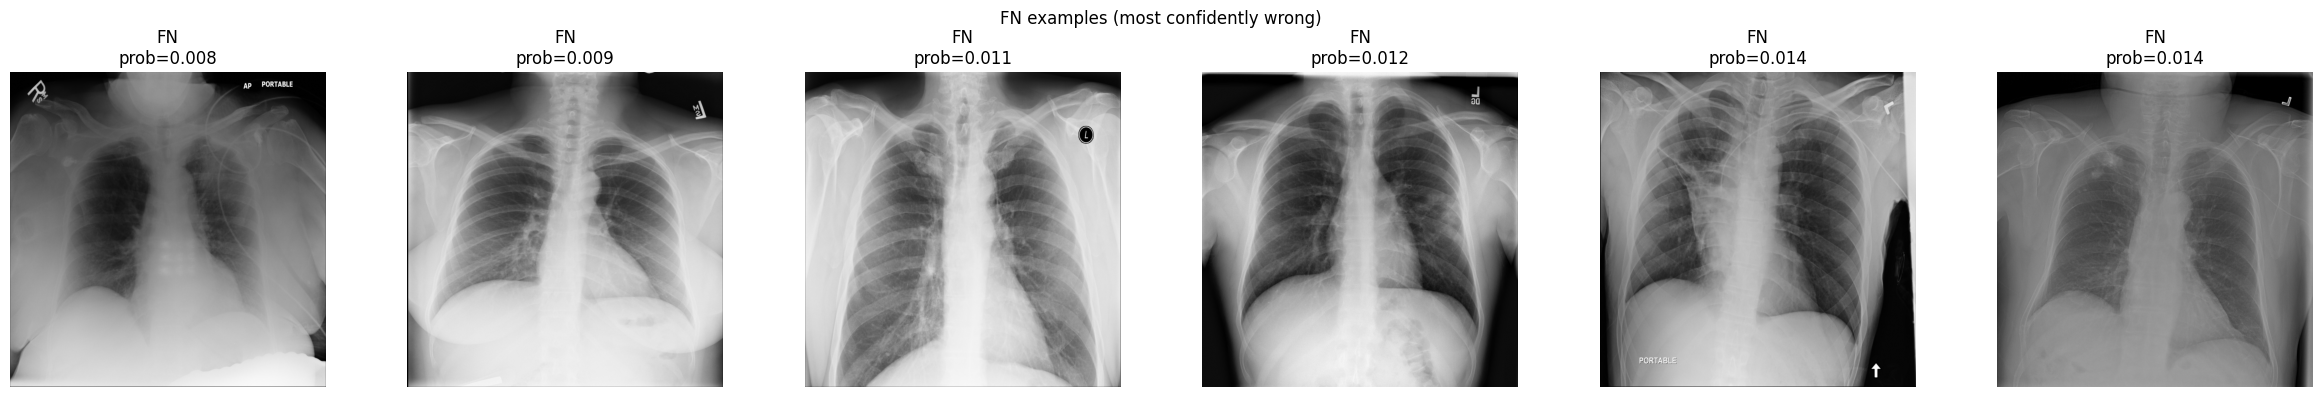

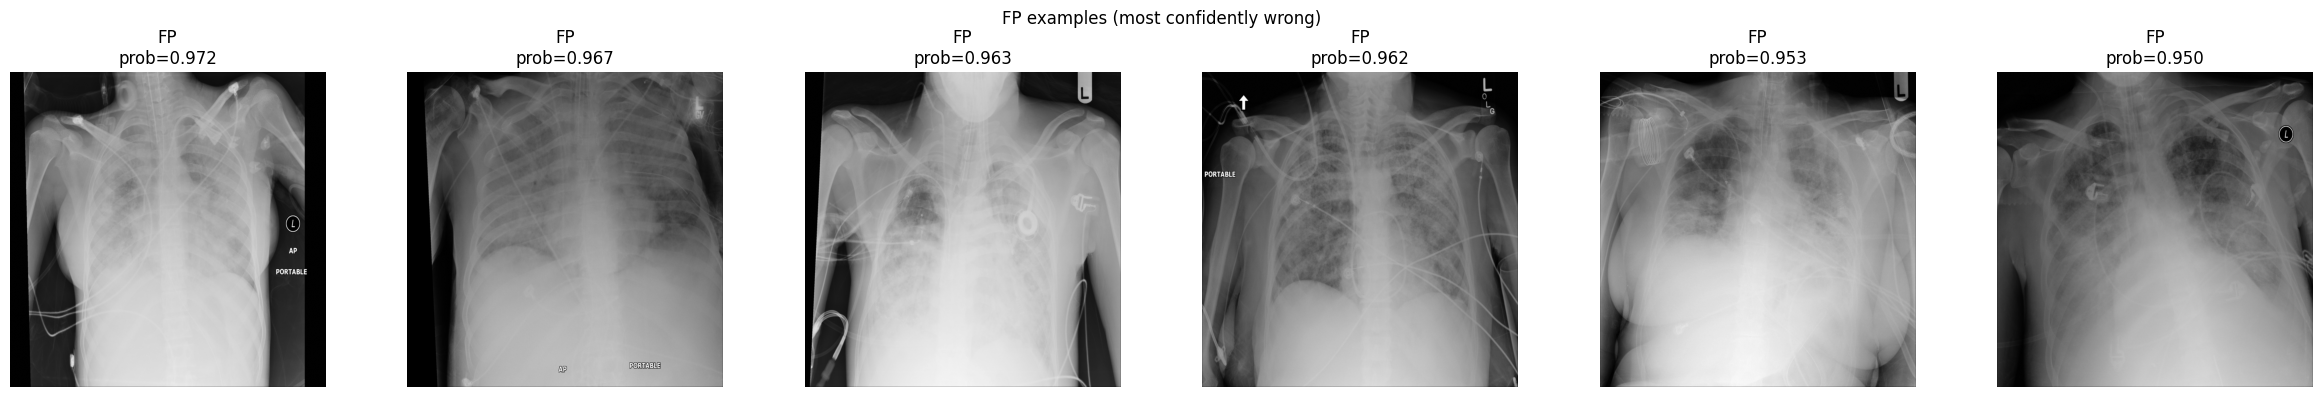

In [ ]:
show_examples(val_df, 'FN', n=6)
show_examples(val_df, 'FP', n=6)

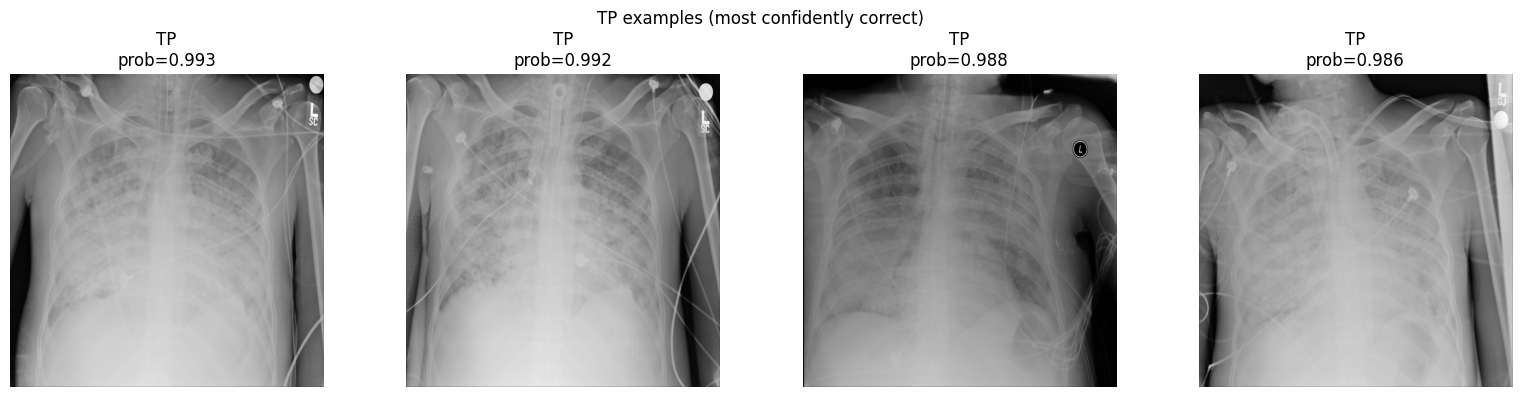

In [ ]:
show_examples(val_df, 'TP', n=4)

In [ ]:
def disable_inplace_relu(model):
    for module in model.modules():
        if isinstance(module, nn.ReLU):
            module.inplace = False

disable_inplace_relu(densenet_model)
print("In-place ReLUs disabled for Grad-CAM compatibility.")

In-place ReLUs disabled for Grad-CAM compatibility.


In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * self.activations).sum(dim=1).squeeze()
        cam = torch.relu(cam)

        cam = cam.cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.sigmoid(output).item()

In [ ]:
densenet_model = build_densenet121(freeze_backbone=False).to(device)
densenet_model.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_stage2_finetuned.pt'))
densenet_model.eval()

print("DenseNet121 reloaded fresh - no stale hooks.")

DenseNet121 reloaded fresh - no stale hooks.


In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, input, output):
        self.activations = output
        self.activations.retain_grad()

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.backward()

        gradients = self.activations.grad
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1).squeeze()
        cam = torch.relu(cam)

        cam = cam.detach().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.sigmoid(output).item()

In [ ]:
target_layer = densenet_model.features.norm5
grad_cam = GradCAM(densenet_model, target_layer)

fp_row = val_df[val_df['result']=='FP'].sort_values('prob', ascending=False).iloc[0]
print("Testing on patient:", fp_row['patientId'], "| model prob:", fp_row['prob'])

img_tensor, _ = RSNAPneumoniaDataset(
    pd.DataFrame([{'patientId': fp_row['patientId'], 'Target': fp_row['true']}]),
    train_dir, augment=False
)[0]
img_tensor = img_tensor.unsqueeze(0).to(device)
img_tensor.requires_grad = False

cam, prob = grad_cam.generate(img_tensor)
print("Heatmap generated. Confirmed prob:", prob)

Testing on patient: 7c206793-4723-4655-b36f-71486cc0a063 | model prob: 0.9717263
Heatmap generated. Confirmed prob: 0.9717262983322144


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


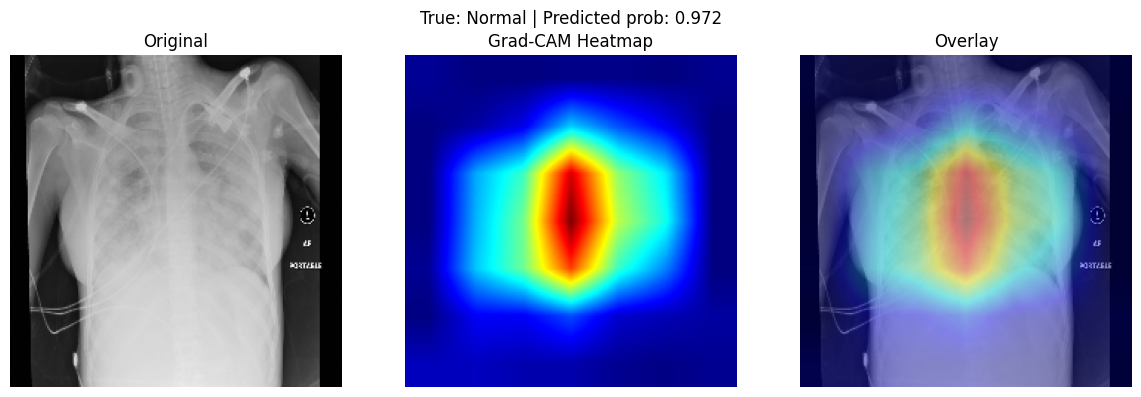

In [ ]:
def show_gradcam(patient_id, cam, prob, true_label):
    ds = pydicom.dcmread(f"{train_dir}/{patient_id}.dcm")
    orig = cv2.resize(ds.pixel_array, (224, 224))

    heatmap = (cam * 255).astype(np.uint8)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    orig_rgb = cv2.cvtColor(orig, cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(orig_rgb, 0.6, heatmap, 0.4, 0)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(orig, cmap='gray'); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(heatmap); axes[1].set_title('Grad-CAM Heatmap'); axes[1].axis('off')
    axes[2].imshow(overlay); axes[2].set_title('Overlay'); axes[2].axis('off')
    plt.suptitle(f"True: {'Pneumonia' if true_label==1 else 'Normal'} | Predicted prob: {prob:.3f}")
    plt.tight_layout()
    plt.show()

show_gradcam(fp_row['patientId'], cam, prob, fp_row['true'])

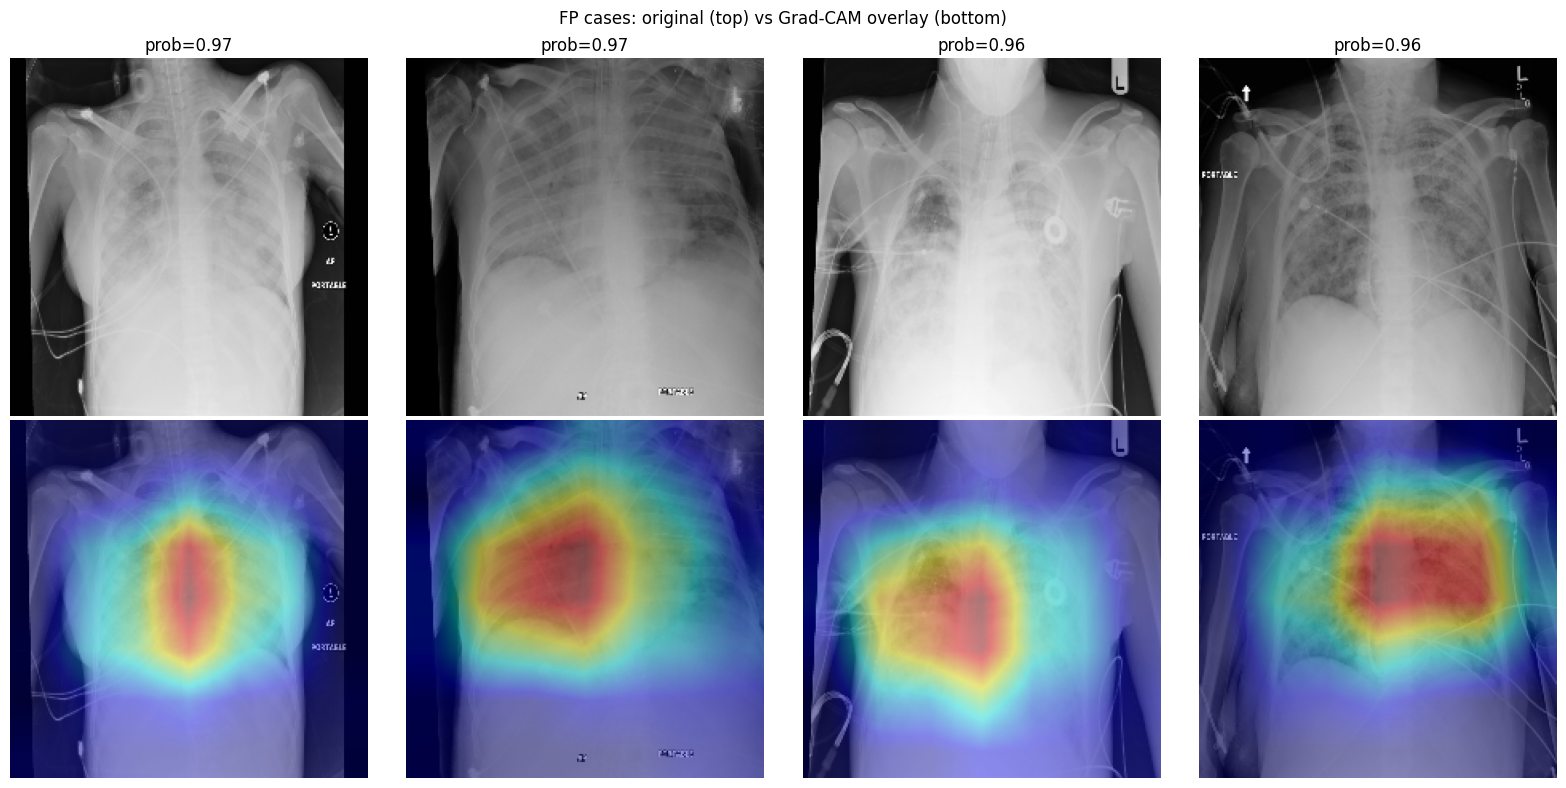

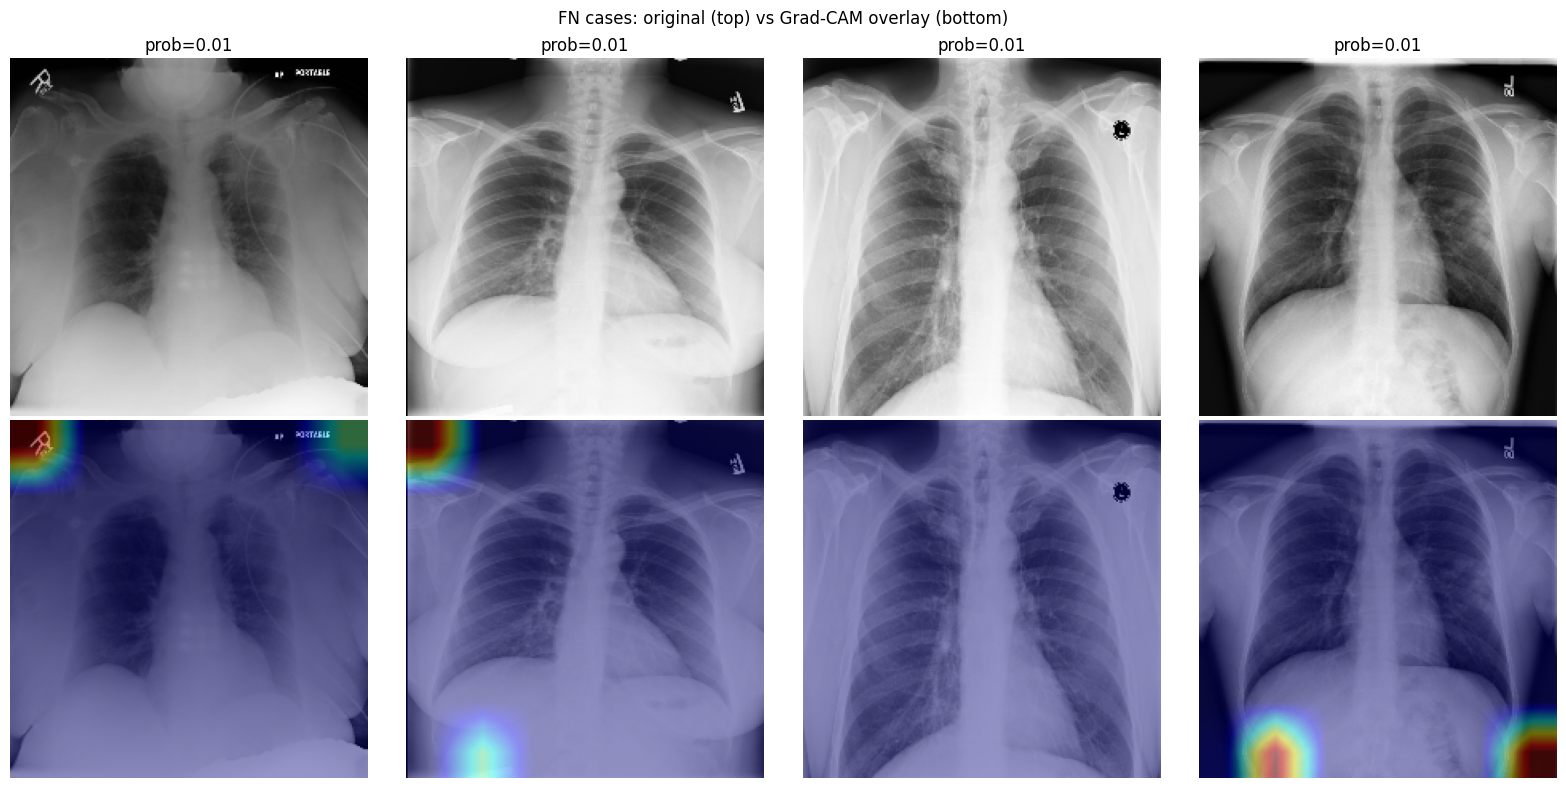

In [ ]:
def gradcam_batch(df, category, n=4, sort_ascending=None):
    subset = df[df['result'] == category].copy()
    if sort_ascending is None:
        sort_ascending = (category == 'FN')
    subset = subset.sort_values('prob', ascending=sort_ascending).head(n)

    fig, axes = plt.subplots(2, n, figsize=(4*n, 8))
    for i, (_, row) in enumerate(subset.iterrows()):
        img_tensor, _ = RSNAPneumoniaDataset(
            pd.DataFrame([{'patientId': row['patientId'], 'Target': row['true']}]),
            train_dir, augment=False
        )[0]
        img_tensor = img_tensor.unsqueeze(0).to(device)
        cam, prob = grad_cam.generate(img_tensor)

        ds = pydicom.dcmread(f"{train_dir}/{row['patientId']}.dcm")
        orig = cv2.resize(ds.pixel_array, (224, 224))
        heatmap = cv2.applyColorMap((cam*255).astype(np.uint8), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        orig_rgb = cv2.cvtColor(orig, cv2.COLOR_GRAY2RGB)
        overlay = cv2.addWeighted(orig_rgb, 0.6, heatmap, 0.4, 0)

        axes[0, i].imshow(orig, cmap='gray'); axes[0, i].axis('off')
        axes[0, i].set_title(f"prob={prob:.2f}")
        axes[1, i].imshow(overlay); axes[1, i].axis('off')

    plt.suptitle(f"{category} cases: original (top) vs Grad-CAM overlay (bottom)")
    plt.tight_layout()
    plt.show()

gradcam_batch(val_df, 'FP', n=4)
gradcam_batch(val_df, 'FN', n=4)

Expected Calibration Error (ECE): 0.6293


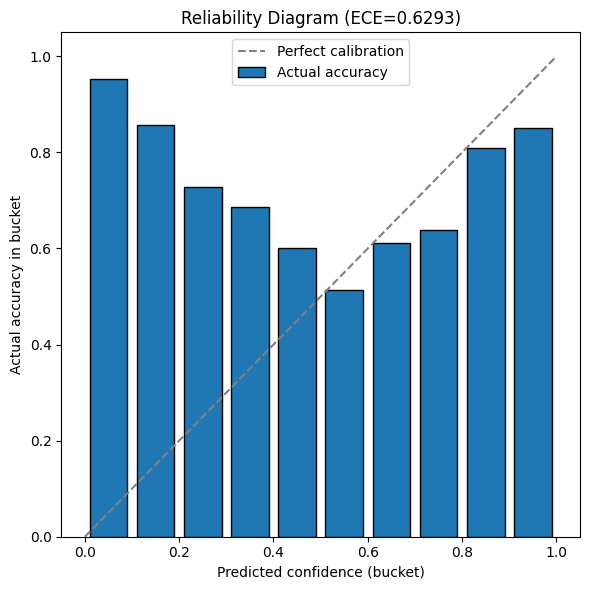

In [ ]:
def compute_ece_and_reliability(probs, labels, n_bins=10):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_accs, bin_confs, bin_counts = [], [], []
    ece = 0
    n = len(probs)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i+1]
        in_bin = (probs > lo) & (probs <= hi) if i > 0 else (probs >= lo) & (probs <= hi)
        count = in_bin.sum()
        if count > 0:
            acc = (labels[in_bin] == (probs[in_bin] > 0.5)).mean()
            conf = probs[in_bin].mean()
            ece += (count / n) * abs(acc - conf)
        else:
            acc, conf = 0, 0
        bin_accs.append(acc)
        bin_confs.append(conf)
        bin_counts.append(count)

    return ece, bin_edges, bin_accs, bin_confs, bin_counts

ece, bin_edges, bin_accs, bin_confs, bin_counts = compute_ece_and_reliability(densenet_probs, val_labels)
print(f"Expected Calibration Error (ECE): {ece:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax.bar(bin_centers, bin_accs, width=0.08, edgecolor='black', label='Actual accuracy')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
ax.set_xlabel('Predicted confidence (bucket)')
ax.set_ylabel('Actual accuracy in bucket')
ax.set_title(f'Reliability Diagram (ECE={ece:.4f})')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
densenet_model = build_densenet121(freeze_backbone=False).to(device)
densenet_model.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_stage2_finetuned.pt'))
densenet_model.eval()
print("DenseNet121 reloaded fresh - hooks cleared.")

DenseNet121 reloaded fresh - hooks cleared.


In [ ]:
def get_raw_logits(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            all_logits.extend(outputs.cpu().numpy().flatten())
            all_labels.extend(labels.numpy())
    return np.array(all_logits), np.array(all_labels)

val_logits, val_labels_check = get_raw_logits(densenet_model, val_loader, device)
print("Logits range:", val_logits.min(), "to", val_logits.max())

Logits range: -7.3841634 to 4.9404454


In [ ]:
val_logits_t = torch.tensor(val_logits, dtype=torch.float32).to(device)
val_labels_t = torch.tensor(val_labels_check, dtype=torch.float32).to(device)

T = torch.nn.Parameter(torch.ones(1).to(device))
optimizer_T = optim.LBFGS([T], lr=0.01, max_iter=50)
criterion = nn.BCEWithLogitsLoss()

def closure():
    optimizer_T.zero_grad()
    scaled_logits = val_logits_t / T
    loss = criterion(scaled_logits, val_labels_t)
    loss.backward()
    return loss

optimizer_T.step(closure)
print(f"Learned temperature T = {T.item():.4f}")

Learned temperature T = 1.0464


ECE before calibration: 0.6293
ECE after calibration:  0.6234


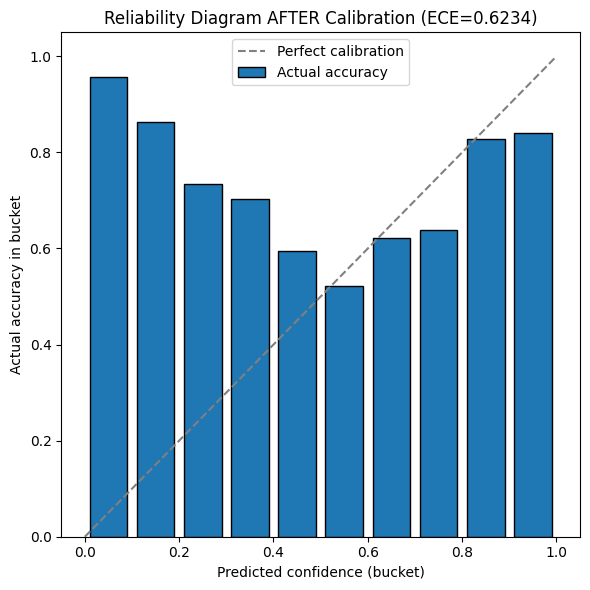

In [ ]:
with torch.no_grad():
    calibrated_probs = torch.sigmoid(val_logits_t / T).cpu().numpy()

ece_calibrated, bin_edges2, bin_accs2, bin_confs2, bin_counts2 = compute_ece_and_reliability(calibrated_probs, val_labels_check)
print(f"ECE before calibration: {ece:.4f}")
print(f"ECE after calibration:  {ece_calibrated:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
bin_centers = (bin_edges2[:-1] + bin_edges2[1:]) / 2
ax.bar(bin_centers, bin_accs2, width=0.08, edgecolor='black', label='Actual accuracy')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
ax.set_xlabel('Predicted confidence (bucket)')
ax.set_ylabel('Actual accuracy in bucket')
ax.set_title(f'Reliability Diagram AFTER Calibration (ECE={ece_calibrated:.4f})')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("Shape:", calibrated_probs.shape)
print("Min/max:", calibrated_probs.min(), calibrated_probs.max())
print("Sample values:", calibrated_probs[:5])

Shape: (4003,)
Min/max: 0.0008606255 0.9911772
Sample values: [0.01417375 0.03371432 0.01030169 0.88806456 0.01582091]


In [ ]:
def compute_ece_and_reliability(probs, labels, n_bins=10):
    probs = np.asarray(probs).flatten()
    labels = np.asarray(labels).flatten()

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_accs, bin_confs, bin_counts = [], [], []
    ece = 0
    n = len(probs)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i+1]
        in_bin = (probs > lo) & (probs <= hi) if i > 0 else (probs >= lo) & (probs <= hi)
        count = int(in_bin.sum())
        if count > 0:
            acc = float((labels[in_bin] == (probs[in_bin] > 0.5)).mean())
            conf = float(probs[in_bin].mean())
            contribution = (count / n) * abs(acc - conf)
            ece += contribution
            print(f"Bin {lo:.1f}-{hi:.1f}: count={count}, acc={acc:.3f}, conf={conf:.3f}, contributes={contribution:.4f}")
        else:
            acc, conf = 0, 0
        bin_accs.append(acc)
        bin_confs.append(conf)
        bin_counts.append(count)

    return ece, bin_edges, bin_accs, bin_confs, bin_counts

ece_calibrated, bin_edges2, bin_accs2, bin_confs2, bin_counts2 = compute_ece_and_reliability(calibrated_probs, val_labels_check)
print(f"\nFinal ECE: {ece_calibrated:.4f}")

Bin 0.0-0.1: count=1968, acc=0.956, conf=0.035, contributes=0.4528
Bin 0.1-0.2: count=508, acc=0.864, conf=0.143, contributes=0.0916
Bin 0.2-0.3: count=308, acc=0.734, conf=0.244, contributes=0.0377
Bin 0.3-0.4: count=262, acc=0.702, conf=0.349, contributes=0.0231
Bin 0.4-0.5: count=220, acc=0.595, conf=0.448, contributes=0.0081
Bin 0.5-0.6: count=180, acc=0.522, conf=0.551, contributes=0.0013
Bin 0.6-0.7: count=143, acc=0.622, conf=0.647, contributes=0.0009
Bin 0.7-0.8: count=155, acc=0.639, conf=0.753, contributes=0.0044
Bin 0.8-0.9: count=152, acc=0.829, conf=0.853, contributes=0.0009
Bin 0.9-1.0: count=107, acc=0.841, conf=0.939, contributes=0.0026

Final ECE: 0.6234


In [ ]:
def compute_ece_and_reliability(probs, labels, n_bins=10):
    probs = np.asarray(probs).flatten()
    labels = np.asarray(labels).flatten()

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_fracpos, bin_confs, bin_counts = [], [], []
    ece = 0
    n = len(probs)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i+1]
        in_bin = (probs > lo) & (probs <= hi) if i > 0 else (probs >= lo) & (probs <= hi)
        count = int(in_bin.sum())
        if count > 0:
            frac_pos = float(labels[in_bin].mean())
            conf = float(probs[in_bin].mean())
            contribution = (count / n) * abs(frac_pos - conf)
            ece += contribution
            print(f"Bin {lo:.1f}-{hi:.1f}: count={count}, actual_pos_rate={frac_pos:.3f}, mean_pred={conf:.3f}, contributes={contribution:.4f}")
        else:
            frac_pos, conf = 0, 0
        bin_fracpos.append(frac_pos)
        bin_confs.append(conf)
        bin_counts.append(count)

    return ece, bin_edges, bin_fracpos, bin_confs, bin_counts

print("--- BEFORE calibration ---")
ece_before, be1, bf1, bc1, bcount1 = compute_ece_and_reliability(densenet_probs, val_labels)
print(f"ECE before: {ece_before:.4f}\n")

print("--- AFTER calibration ---")
ece_after, be2, bf2, bc2, bcount2 = compute_ece_and_reliability(calibrated_probs, val_labels_check)
print(f"ECE after: {ece_after:.4f}")

--- BEFORE calibration ---
Bin 0.0-0.1: count=2039, actual_pos_rate=0.047, mean_pred=0.033, contributes=0.0069
Bin 0.1-0.2: count=476, actual_pos_rate=0.143, mean_pred=0.144, contributes=0.0001
Bin 0.2-0.3: count=301, actual_pos_rate=0.272, mean_pred=0.246, contributes=0.0020
Bin 0.3-0.4: count=239, actual_pos_rate=0.314, mean_pred=0.351, contributes=0.0022
Bin 0.4-0.5: count=211, actual_pos_rate=0.398, mean_pred=0.448, contributes=0.0026
Bin 0.5-0.6: count=173, actual_pos_rate=0.514, mean_pred=0.551, contributes=0.0016
Bin 0.6-0.7: count=139, actual_pos_rate=0.612, mean_pred=0.647, contributes=0.0012
Bin 0.7-0.8: count=147, actual_pos_rate=0.639, mean_pred=0.752, contributes=0.0041
Bin 0.8-0.9: count=158, actual_pos_rate=0.810, mean_pred=0.852, contributes=0.0017
Bin 0.9-1.0: count=120, actual_pos_rate=0.850, mean_pred=0.941, contributes=0.0027
ECE before: 0.0251

--- AFTER calibration ---
Bin 0.0-0.1: count=1968, actual_pos_rate=0.044, mean_pred=0.035, contributes=0.0042
Bin 0.1-0.2:

In [ ]:
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)

n_pos = float(train_ids['Target'].sum())
n_neg = len(train_ids) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

model_w = build_densenet121(freeze_backbone=False).to(device)
model_w.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_weighted_bestloss.pt'))

optimizer = optim.Adam(model_w.parameters(), lr=1e-5)

ckpt_loss = f'{checkpoint_dir}/densenet121_weighted_bestloss.pt'
ckpt_f1 = f'{checkpoint_dir}/densenet121_weighted_bestf1.pt'

max_epochs, patience = 14, 4
best_val_loss, best_val_f1 = float('inf'), 0.0
epochs_no_improve = 0
history_weighted_resumed = []

for epoch in range(max_epochs):
    train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(model_w, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model_w, val_loader, criterion, device)

    history_weighted_resumed.append({'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss,
                             'val_acc': val_acc, 'val_prec': val_prec, 'val_rec': val_rec, 'val_f1': val_f1})

    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} val_prec={val_prec:.4f} val_rec={val_rec:.4f} val_f1={val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model_w.state_dict(), ckpt_f1)
        print("  -> saved best-F1 model")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model_w.state_dict(), ckpt_loss)
        print("  -> saved best-loss model")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

Validating: 100%|██████████| 126/126 [00:52<00:00,  2.42it/s]


Epoch 1: train_loss=0.7031 val_loss=0.7236 | val_acc=0.7674 val_prec=0.4899 val_rec=0.7805 val_f1=0.6020
  -> saved best-F1 model
  -> saved best-loss model


Validating: 100%|██████████| 126/126 [00:51<00:00,  2.43it/s]


Epoch 2: train_loss=0.6553 val_loss=0.7126 | val_acc=0.7749 val_prec=0.5003 val_rec=0.7949 val_f1=0.6141
  -> saved best-F1 model
  -> saved best-loss model


Validating: 100%|██████████| 126/126 [00:52<00:00,  2.42it/s]


...

Epoch 4: train_loss=0.5906 val_loss=0.7219 | val_acc=0.7792 val_prec=0.5065 val_rec=0.7761 val_f1=0.6130


Validating: 100%|██████████| 126/126 [00:52<00:00,  2.39it/s]


Epoch 5: train_loss=0.5569 val_loss=0.7215 | val_acc=0.7897 val_prec=0.5225 val_rec=0.7738 val_f1=0.6238
  -> saved best-F1 model


Validating: 100%|██████████| 126/126 [00:52<00:00,  2.40it/s]

Epoch 6: train_loss=0.5251 val_loss=0.7468 | val_acc=0.7889 val_prec=0.5219 val_rec=0.7528 val_f1=0.6164
Early stopping at epoch 6


In [5]:
densenet_unweighted = build_densenet121(freeze_backbone=False).to(device)
densenet_unweighted.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_stage2_finetuned.pt'))
densenet_unweighted.eval()

densenet_weighted_loss = build_densenet121(freeze_backbone=False).to(device)
densenet_weighted_loss.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_weighted_bestloss.pt'))
densenet_weighted_loss.eval()

densenet_weighted_f1 = build_densenet121(freeze_backbone=False).to(device)
densenet_weighted_f1.load_state_dict(torch.load(f'{checkpoint_dir}/densenet121_weighted_bestf1.pt'))
densenet_weighted_f1.eval()

print("All 3 DenseNet121 variants loaded.")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 77.0MB/s]


All 3 DenseNet121 variants loaded.


In [7]:
print(uw_probs.shape, wl_probs.shape, wf1_probs.shape, val_labels_check.shape)

(4003,) (4003,) (4003,) (4003,)


In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

def full_metrics(name, probs, preds, labels):
    acc = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, zero_division=0)
    rec = recall_score(labels, preds, zero_division=0)
    f1 = f1_score(labels, preds, zero_division=0)
    roc_auc = roc_auc_score(labels, probs)
    pr_auc = average_precision_score(labels, probs)
    cm = confusion_matrix(labels, preds)

    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
    print(f"Confusion Matrix:\n{cm}")
    print()

    return {'name': name, 'accuracy': acc, 'precision': prec, 'recall': rec,
            'f1': f1, 'roc_auc': roc_auc, 'pr_auc': pr_auc, 'confusion_matrix': cm}

r_unweighted = full_metrics("DenseNet121 (unweighted)", uw_probs, uw_preds, val_labels_check)
r_weighted_loss = full_metrics("DenseNet121 (weighted, best-loss ckpt)", wl_probs, wl_preds, val_labels_check)
r_weighted_f1 = full_metrics("DenseNet121 (weighted, best-F1 ckpt)", wf1_probs, wf1_preds, val_labels_check)

--- DenseNet121 (unweighted) ---
Accuracy: 0.8394 | Precision: 0.6757 | Recall: 0.5521 | F1: 0.6077
ROC-AUC: 0.8667 | PR-AUC: 0.6687
Confusion Matrix:
[[2862  239]
 [ 404  498]]

--- DenseNet121 (weighted, best-loss ckpt) ---
Accuracy: 0.7749 | Precision: 0.5003 | Recall: 0.7949 | F1: 0.6141
ROC-AUC: 0.8656 | PR-AUC: 0.6648
Confusion Matrix:
[[2385  716]
 [ 185  717]]

--- DenseNet121 (weighted, best-F1 ckpt) ---
Accuracy: 0.7897 | Precision: 0.5225 | Recall: 0.7738 | F1: 0.6238
ROC-AUC: 0.8684 | PR-AUC: 0.6595
Confusion Matrix:
[[2463  638]
 [ 204  698]]



For this project F1 is the basis for chosing the best model that works well because the major to tackle is the false negative

In [9]:
def get_raw_logits(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            all_logits.extend(outputs.cpu().numpy().flatten())
            all_labels.extend(labels.numpy())
    return np.array(all_logits), np.array(all_labels)

val_logits_w, val_labels_w = get_raw_logits(densenet_weighted_f1, val_loader, device)

val_logits_wt = torch.tensor(val_logits_w, dtype=torch.float32).to(device)
val_labels_wt = torch.tensor(val_labels_w, dtype=torch.float32).to(device)

T_w = torch.nn.Parameter(torch.ones(1).to(device))
optimizer_T = optim.LBFGS([T_w], lr=0.01, max_iter=50)
criterion_ce = nn.BCEWithLogitsLoss()

def closure():
    optimizer_T.zero_grad()
    loss = criterion_ce(val_logits_wt / T_w, val_labels_wt)
    loss.backward()
    return loss

optimizer_T.step(closure)
FINAL_TEMPERATURE = T_w.item()
print(f"Learned temperature for final model: {FINAL_TEMPERATURE:.4f}")

Learned temperature for final model: 1.0842


In [11]:
import pydicom
from PIL import Image

def predict_xray(file_path, model=densenet_weighted_f1, temperature=FINAL_TEMPERATURE, device=device):
    """
    Full inference pipeline: file path -> prediction, confidence, Grad-CAM overlay.
    Handles: invalid files, wrong formats, unexpected dimensions.
    Returns a dict with results, or a dict with an 'error' key on failure.
    """

    try:
        if file_path.lower().endswith('.dcm'):
            ds = pydicom.dcmread(file_path)
            img_array = ds.pixel_array.astype(np.float32)
        else:
            pil_img = Image.open(file_path).convert('L')
            img_array = np.array(pil_img).astype(np.float32)
    except Exception as e:
        return {'error': f'Could not read image file: {str(e)}'}


    if img_array.ndim != 2:
        return {'error': f'Expected a 2D grayscale image, got shape {img_array.shape}'}
    if img_array.shape[0] < 32 or img_array.shape[1] < 32:
        return {'error': f'Image too small to be a valid X-ray: {img_array.shape}'}


    try:
        img_resized = cv2.resize(img_array, (224, 224))
        img_rgb = np.stack([img_resized] * 3, axis=-1)
        img_norm = img_rgb / 255.0
        img_norm = (img_norm - IMAGENET_MEAN) / IMAGENET_STD
        img_tensor = torch.tensor(img_norm, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    except Exception as e:
        return {'error': f'Preprocessing failed: {str(e)}'}


    try:
        model.eval()
        with torch.no_grad():
            logit = model(img_tensor)
            raw_prob = torch.sigmoid(logit).item()
            calibrated_prob = torch.sigmoid(logit / temperature).item()
    except Exception as e:
        return {'error': f'Model inference failed: {str(e)}'}

    prediction = 'Pneumonia' if calibrated_prob > 0.5 else 'Normal'


    try:
        gradcam_model = build_densenet121(freeze_backbone=False).to(device)
        gradcam_model.load_state_dict(model.state_dict())
        target_layer = gradcam_model.features.norm5
        gcam = GradCAM(gradcam_model, target_layer)
        cam, _ = gcam.generate(img_tensor)

        heatmap = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        orig_rgb = cv2.cvtColor(img_resized.astype(np.uint8), cv2.COLOR_GRAY2RGB)
        overlay = cv2.addWeighted(orig_rgb, 0.6, heatmap, 0.4, 0)
    except Exception as e:
        overlay = None
        heatmap = None
        print(f"Warning: Grad-CAM generation failed: {str(e)}")

    return {
        'prediction': prediction,
        'confidence': calibrated_prob,
        'raw_confidence': raw_prob,
        'original_image': img_resized,
        'gradcam_heatmap': heatmap,
        'gradcam_overlay': overlay,
        'error': None
    }

In [13]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, input, output):
        self.activations = output
        self.activations.retain_grad()

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.backward()

        gradients = self.activations.grad
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1).squeeze()
        cam = torch.relu(cam)

        cam = cam.detach().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.sigmoid(output).item()

Prediction: Normal
Confidence: 5.6%
True label: Normal


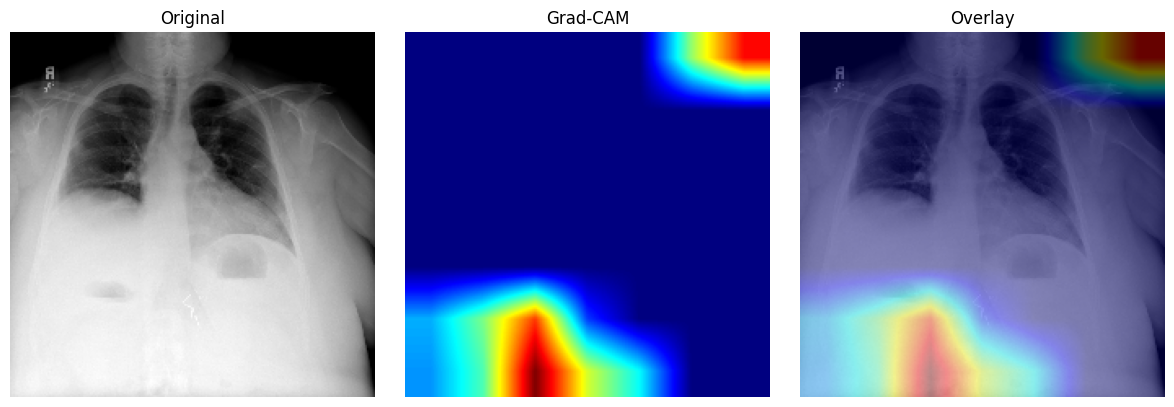

In [14]:
test_patient = val_ids.iloc[0]
test_path = f"{train_dir}/{test_patient['patientId']}.dcm"

result = predict_xray(test_path)

if result['error']:
    print("ERROR:", result['error'])
else:
    print(f"Prediction: {result['prediction']}")
    print(f"Confidence: {result['confidence']*100:.1f}%")
    print(f"True label: {'Pneumonia' if test_patient['Target']==1 else 'Normal'}")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(result['original_image'], cmap='gray'); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(result['gradcam_heatmap']); axes[1].set_title('Grad-CAM'); axes[1].axis('off')
    axes[2].imshow(result['gradcam_overlay']); axes[2].set_title('Overlay'); axes[2].axis('off')
    plt.tight_layout()
    plt.show()

In [16]:
inference_code = '''
import torch
import numpy as np
import cv2
import pydicom
from PIL import Image

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, input, output):
        self.activations = output
        self.activations.retain_grad()

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.backward()

        gradients = self.activations.grad
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1).squeeze()
        cam = torch.relu(cam)

        cam = cam.detach().cpu().numpy()
        cam = cv2.resize(cam, (224, 224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.sigmoid(output).item()


def predict_xray(file_path, model, build_model_fn, temperature, device):
    """
    Full inference pipeline: file path -> prediction, confidence, Grad-CAM overlay.
    build_model_fn: a zero-arg-callable-style function reference used to build a fresh
    model instance for Grad-CAM (pass build_densenet121 partially applied, or similar).
    """
    try:
        if file_path.lower().endswith(".dcm"):
            ds = pydicom.dcmread(file_path)
            img_array = ds.pixel_array.astype(np.float32)
        else:
            pil_img = Image.open(file_path).convert("L")
            img_array = np.array(pil_img).astype(np.float32)
    except Exception as e:
        return {"error": f"Could not read image file: {str(e)}"}

    if img_array.ndim != 2:
        return {"error": f"Expected a 2D grayscale image, got shape {img_array.shape}"}
    if img_array.shape[0] < 32 or img_array.shape[1] < 32:
        return {"error": f"Image too small to be a valid X-ray: {img_array.shape}"}

    try:
        img_resized = cv2.resize(img_array, (224, 224))
        img_rgb = np.stack([img_resized] * 3, axis=-1)
        img_norm = img_rgb / 255.0
        img_norm = (img_norm - IMAGENET_MEAN) / IMAGENET_STD
        img_tensor = torch.tensor(img_norm, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    except Exception as e:
        return {"error": f"Preprocessing failed: {str(e)}"}

    try:
        model.eval()
        with torch.no_grad():
            logit = model(img_tensor)
            raw_prob = torch.sigmoid(logit).item()
            calibrated_prob = torch.sigmoid(logit / temperature).item()
    except Exception as e:
        return {"error": f"Model inference failed: {str(e)}"}

    prediction = "Pneumonia" if calibrated_prob > 0.5 else "Normal"

    try:
        gradcam_model = build_model_fn().to(device)
        gradcam_model.load_state_dict(model.state_dict())
        target_layer = gradcam_model.features.norm5
        gcam = GradCAM(gradcam_model, target_layer)
        cam, _ = gcam.generate(img_tensor)

        heatmap = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        orig_rgb = cv2.cvtColor(img_resized.astype(np.uint8), cv2.COLOR_GRAY2RGB)
        overlay = cv2.addWeighted(orig_rgb, 0.6, heatmap, 0.4, 0)
    except Exception as e:
        overlay = None
        heatmap = None
        print(f"Warning: Grad-CAM generation failed: {str(e)}")

    return {
        "prediction": prediction,
        "confidence": calibrated_prob,
        "raw_confidence": raw_prob,
        "original_image": img_resized,
        "gradcam_heatmap": heatmap,
        "gradcam_overlay": overlay,
        "error": None
    }
'''

import os
src_dir = '/content/drive/MyDrive/medical-image-classification/src/evaluation'
os.makedirs(src_dir, exist_ok=True)
with open(f'{src_dir}/inference.py', 'w') as f:
    f.write(inference_code)

print("Saved to:", f'{src_dir}/inference.py')

Saved to: /content/drive/MyDrive/medical-image-classification/src/evaluation/inference.py
